# Catálogo de cámaras - Análisis Exploratorio de los Datos

El objetivo de este notebook es la realización de un **análisis exploratorio de los datos (EDA)** del catálogo de cámaras con el objetivo de conocer:

- El número de cámaras existentes
- La ubicación de las cámaras
- La información técnica asociada a las cámaras
- La cobertura que ofrecen para cada distrito

## Cuestiones previas

Se ha seleccionado el **Ayuntamiento de Málaga** como ámbito de aplicación.

Los datos de sus cámaras de tráfico son públicos. No expone una API pública ni endpoints estables para descarga masiva de vídeo. Por este motivo, se ha realizado una extracción de las imágenes mediante un script de cara a trabajar con ellas localmente.

Como parte del conjunto de datos, se incluyen **dos ficheros complementarios** que se describen a continuación:

- Fichero da_camarasTrafico-4326 en formato CSV: contiene los datos relevantes de cada cámara de tráfico de la ciudad. Entre otros, destacan:
    - ID y NOMBRE: identificador y nombre de la cámara.
    - DESCRIPCION y DIRECCION: texto descriptivo y dirección postal de la cámara.
    - SDOGEOMETRIA: coordenadas de la cámara en formato `POINT (lon lat)` (EPSG:4326).
    - URLIMAGEN: enlace a la imagen en tiempo real.

- Fichero da_camarasTrafico-4326 en formato GEOJSON: datos similares al dataset anterior, pero orientado a las propiedades y geometría espacial de las cámaras.

## Librerías y configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from catalogo import load_catalog
from config import path

CSV_FILE = path("catalogo")
RANDOM_SEED = 42
pd.set_option("display.max_columns", None)
print(f"Archivo CSV: {CSV_FILE}")

Archivo CSV: C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\da_camarasTrafico-4326.csv


## Carga de datos

Se carga el dataset principal y se validan dimensiones y tipos. `load_catalog` deriva `lat`/`lon` de `SDOGEOMETRIA` (el CSV no trae esas columnas) y limpia los espacios y tabuladores de `URLIMAGEN`.

In [2]:
if not CSV_FILE.exists():
    raise FileNotFoundError(f"No existe el archivo: {CSV_FILE}")

df = load_catalog(CSV_FILE)
print("Registros:", len(df))
print("Columnas:", len(df.columns))
print("Cámaras sin coordenadas:", df[["lat", "lon"]].isna().any(axis=1).sum())

display(df.head())
df.info()

Registros: 134
Columnas: 17
Cámaras sin coordenadas: 0


,FID,ID,NOMBRE,DESCRIPCION,DIRECCION,SDOGEOMETRIA,URL,EMAIL,CONTACTO,HORARIOS,PRECIOS,TITULARIDAD,TARJETAJOVEN,ACCESOPMR,URLIMAGEN,lat,lon
0,da_camarasTrafico.fid--3b3f458b_19b968d046b_cbe,21611,TV87-EL BONI - CAMPANILLAS,C/ José Calderón - El Boni,"CALLE JOSÉ CALDERÓN, 45",POINT (-4.539062997820292 36.72406291352086),https://movilidad.malaga.eu/es/servicios/camar...,NaN,NaN,NaN,NaN,MUNICIPAL,No,No,https://ctraficomovilidad.malaga.eu/recursos/m...,36.724063,-4.539063
1,da_camarasTrafico.fid--3b3f458b_19b968d046b_cbf,75066,TV100-JOSÉ CALDERÓN - JUNTA DE DISTRITO CAMPAN...,José Calderón - Junta De Distrito Campanillas,"CALLE JOSÉ CALDERÓN, 174",POINT (-4.544862290941862 36.72806421666882),https://movilidad.malaga.eu/es/servicios/camar...,NaN,NaN,NaN,NaN,MUNICIPAL,No,No,https://ctraficomovilidad.malaga.eu/recursos/m...,36.728064,-4.544862
2,da_camarasTrafico.fid--3b3f458b_19b968d046b_cc0,75086,TV120-HERMANOS LUMIERE - LICURGO,Hermanos Lumiere - Licurgo,"CALLE HERMANOS LUMIÈRE, 14",POINT (-4.4627101617254334 36.69370759993173),https://movilidad.malaga.eu/es/servicios/camar...,NaN,NaN,NaN,NaN,MUNICIPAL,No,No,https://ctraficomovilidad.malaga.eu/recursos/m...,36.693708,-4.462710
3,da_camarasTrafico.fid--3b3f458b_19b968d046b_cc1,75093,TV127-CARRIL DEL CAPITÁN - JUAN DE ROBLES,Carril Del Capitán - Juan De Robles,"CALLE JUAN DE ROBLES, 55",POINT (-4.46161103014071 36.721554097509305),https://movilidad.malaga.eu/es/servicios/camar...,NaN,NaN,NaN,NaN,MUNICIPAL,No,No,https://ctraficomovilidad.malaga.eu/recursos/m...,36.721554,-4.461611
4,da_camarasTrafico.fid--3b3f458b_19b968d046b_cc2,75069,TV103-AVDA LOS GUINDOS - CMNO DE LA TÉRMICA,Avda Los Guindos - Cmno De La Térmica,"AVENIDA DE LOS GUINDOS, 44",POINT (-4.44701655450928 36.69082158314863),https://movilidad.malaga.eu/es/servicios/camar...,NaN,NaN,NaN,NaN,MUNICIPAL,No,No,https://ctraficomovilidad.malaga.eu/recursos/m...,36.690822,-4.447017


<class 'pandas.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   FID           134 non-null    str    
 1   ID            134 non-null    str    
 2   NOMBRE        134 non-null    str    
 3   DESCRIPCION   131 non-null    str    
 4   DIRECCION     134 non-null    str    
 5   SDOGEOMETRIA  134 non-null    str    
 6   URL           134 non-null    str    
 7   EMAIL         0 non-null      float64
 8   CONTACTO      0 non-null      float64
 9   HORARIOS      0 non-null      float64
 10  PRECIOS       0 non-null      float64
 11  TITULARIDAD   134 non-null    str    
 12  TARJETAJOVEN  134 non-null    str    
 13  ACCESOPMR     134 non-null    str    
 14  URLIMAGEN     134 non-null    string 
 15  lat           134 non-null    float64
 16  lon           134 non-null    float64
dtypes: float64(6), str(10), string(1)
memory usage: 65.8 KB


## Información estadística

,nulos
EMAIL,134
PRECIOS,134
CONTACTO,134
HORARIOS,134
DESCRIPCION,3
FID,0
NOMBRE,0
DIRECCION,0
ID,0
SDOGEOMETRIA,0


,nulos,porcentaje
EMAIL,134,100.00
PRECIOS,134,100.00
CONTACTO,134,100.00
HORARIOS,134,100.00
DESCRIPCION,3,2.24
FID,0,0.00
NOMBRE,0,0.00
DIRECCION,0,0.00
ID,0,0.00
SDOGEOMETRIA,0,0.00


url_imagen_valida
True    134
Name: count, dtype: int64


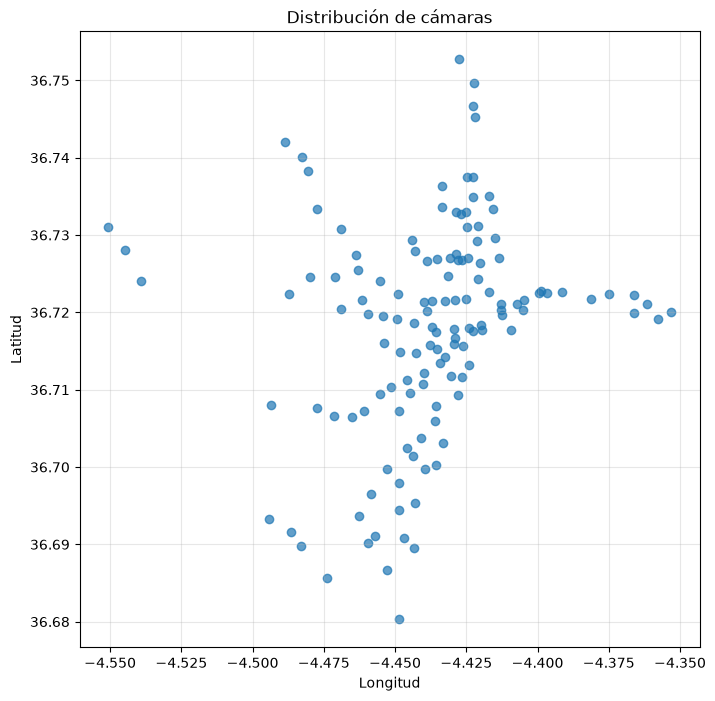

Duplicados: 0


In [3]:
nulls = df.isnull().sum().sort_values(ascending=False).to_frame("nulos")
display(nulls.head(10))

summary = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "porcentaje": round(df.isnull().mean() * 100, 2),
}).sort_values("porcentaje", ascending=False)
display(summary.head(10))

df["url_imagen_valida"] = df["URLIMAGEN"].notna()
print(df["url_imagen_valida"].value_counts())

plt.figure(figsize=(8, 8))
plt.scatter(df["lon"], df["lat"], alpha=0.7)
plt.title("Distribución de cámaras")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.grid(True, alpha=0.3)
plt.show()

duplicados = df.duplicated(subset=["ID"]).sum()
print("Duplicados:", duplicados)

## Ranking de cámaras

In [4]:
display(df[["ID", "NOMBRE", "URLIMAGEN"]].sample(10, random_state=RANDOM_SEED))

print(f"Número de cámaras: {len(df)}")
print(f"URLs imagen válidas: {df['URLIMAGEN'].notna().sum()}")
print(f"Duplicados: {duplicados}")

,ID,NOMBRE,URLIMAGEN
127,21612,TV88. GUERRERO STRACHAN,https://ctraficomovilidad.malaga.eu/recursos/m...
66,75087,TV121-MARTÍNEZ DE LA ROSA - VANDELVIRA,https://ctraficomovilidad.malaga.eu/recursos/m...
104,21549,TV10-PTE AMERICAS,https://ctraficomovilidad.malaga.eu/recursos/m...
19,21545,TV06-PSO PARQUE,https://ctraficomovilidad.malaga.eu/recursos/m...
42,75103,TV99-EMILIO THUILLER - ALCALDE JOAQUÍN QUILES,https://ctraficomovilidad.malaga.eu/recursos/m...
60,21565,TV41-CARRETERÍA,https://ctraficomovilidad.malaga.eu/recursos/m...
12,21546,TV07-BOQUETE DEL MUELLE,https://ctraficomovilidad.malaga.eu/recursos/m...
109,21551,TV12-BERMÚDEZ,https://ctraficomovilidad.malaga.eu/recursos/m...
100,75088,TV122-HÉROE DE SOSTOA - PTE JUAN PABLO II,https://ctraficomovilidad.malaga.eu/recursos/m...
101,21538,TV22-CARLOS HAYA,https://ctraficomovilidad.malaga.eu/recursos/m...


Número de cámaras: 134
URLs imagen válidas: 134
Duplicados: 0


## Siguiente etapa

Con este análisis se ha caracterizado el catálogo de cámaras y su distribución geográfica. La siguiente etapa (`01_EDA_Calidad_Visual.ipynb`) consiste en evaluar la calidad visual de cada imagen para etiquetar qué cámaras son útiles y cuáles deben descartarse.